In [ ]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Downloaded to:", path)

import pandas as pd
df = pd.read_csv(path + "/creditcard.csv")
print(df.shape)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Downloaded to: /kaggle/input/creditcardfraud
(284807, 31)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

In [ ]:
df = pd.read_csv("creditcard.csv")

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.head()

Shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Class
0    284315
1       492
Name: count, dtype: int64
Fraud makes up 0.173% of all transactions


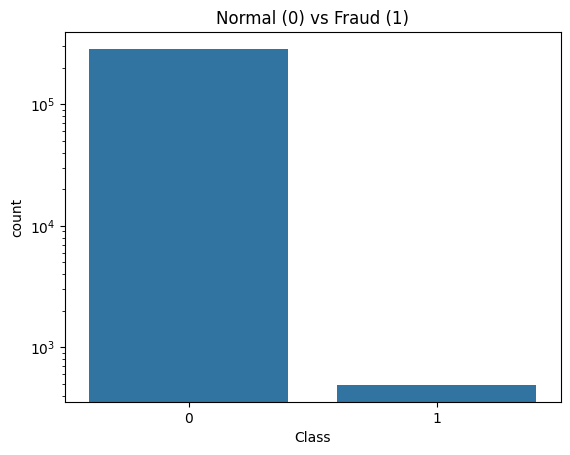

In [ ]:
counts = df["Class"].value_counts()
print(counts)
print(f"Fraud makes up {counts[1] / len(df) * 100:.3f}% of all transactions")

sns.countplot(x="Class", data=df)
plt.title("Normal (0) vs Fraud (1)")
plt.yscale("log")   # log scale so the tiny fraud bar is still visible
plt.show()

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


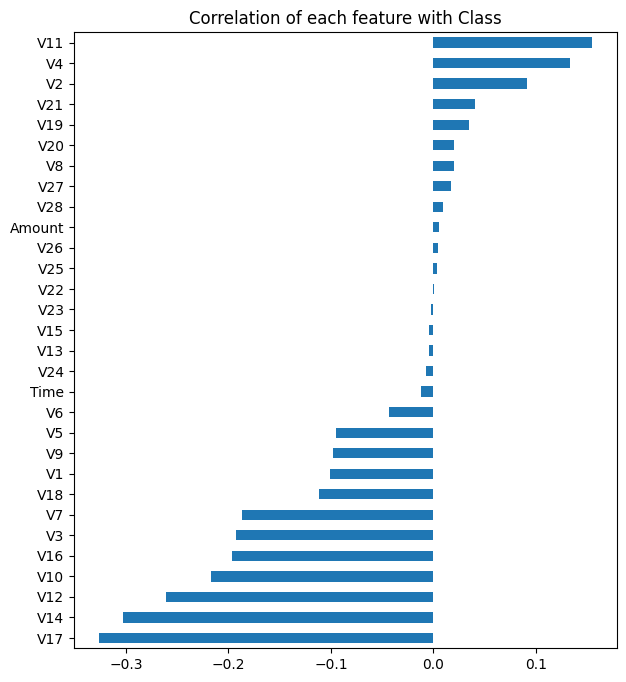

In [ ]:
print(df.groupby("Class")["Amount"].describe())

corr = df.corr()["Class"].drop("Class").sort_values()
corr.plot(kind="barh", figsize=(7, 8), title="Correlation of each feature with Class")
plt.show()

In [ ]:
scaler = StandardScaler()
df["Amount_scaled"] = scaler.fit_transform(df[["Amount"]])
df["Time_scaled"] = scaler.fit_transform(df[["Time"]])
df = df.drop(["Amount", "Time"], axis=1)

X = df.drop("Class", axis=1)
y = df["Class"]

In [ ]:
print("Shape:", df.shape)
print("NaNs in y:", y.isnull().sum())
print(df["Class"].value_counts(dropna=False))
print(df.isnull().sum().sort_values(ascending=False).head())

Shape: (284807, 31)
NaNs in y: 0
Class
0    284315
1       492
Name: count, dtype: int64
V1    0
V2    0
V3    0
V4    0
V5    0
dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Fraud in train:", y_train.sum(), "| Fraud in test:", y_test.sum())

Fraud in train: 394 | Fraud in test: 98


In [ ]:
base_model = LogisticRegression(max_iter=1000)
base_model.fit(X_train, y_train)
base_pred = base_model.predict(X_test)

print(classification_report(y_test, base_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9994    0.9998    0.9996     56864
           1     0.8289    0.6429    0.7241        98

    accuracy                         0.9992     56962
   macro avg     0.9142    0.8213    0.8619     56962
weighted avg     0.9991    0.9992    0.9991     56962



In [ ]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_bal.value_counts().to_dict())

Before SMOTE: {0: 227451, 1: 394}
After SMOTE:  {0: 227451, 1: 227451}


In [ ]:
# Model 1: Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_bal, y_train_bal)

rf_model = RandomForestClassifier(n_estimators=50, max_depth=12,
                                  n_jobs=-1, random_state=42)
rf_model.fit(X_train_bal, y_train_bal)

RandomForestClassifier(max_depth=12, n_estimators=50, n_jobs=-1,
                       random_state=42)

===== Logistic Regression + SMOTE =====
              precision    recall  f1-score   support

           0     0.9999    0.9744    0.9869     56864
           1     0.0581    0.9184    0.1094        98

    accuracy                         0.9743     56962
   macro avg     0.5290    0.9464    0.5481     56962
weighted avg     0.9982    0.9743    0.9854     56962

ROC-AUC: 0.9698
PR-AUC : 0.7249


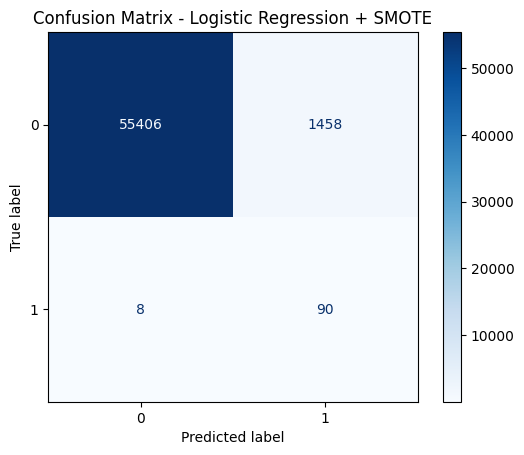

===== Random Forest + SMOTE =====
              precision    recall  f1-score   support

           0     0.9997    0.9987    0.9992     56864
           1     0.5220    0.8469    0.6459        98

    accuracy                         0.9984     56962
   macro avg     0.7609    0.9228    0.8226     56962
weighted avg     0.9989    0.9984    0.9986     56962

ROC-AUC: 0.9746
PR-AUC : 0.8125


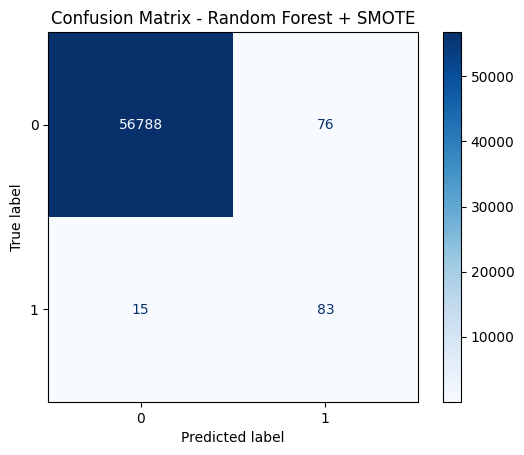

In [67]:
def evaluate(name, model):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    print(f"===== {name} =====")
    print(classification_report(y_test, pred, digits=4))
    print("ROC-AUC:", round(roc_auc_score(y_test, prob), 4))
    print("PR-AUC :", round(average_precision_score(y_test, prob), 4))

    ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

evaluate("Logistic Regression + SMOTE", log_model)
evaluate("Random Forest + SMOTE", rf_model)

In [68]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "ROC-AUC": [roc_auc_score(y_test, log_model.predict_proba(X_test)[:, 1]),
                roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1])],
    "PR-AUC": [average_precision_score(y_test, log_model.predict_proba(X_test)[:, 1]),
               average_precision_score(y_test, rf_model.predict_proba(X_test)[:, 1])],
})
print(results.round(4))

                 Model  ROC-AUC  PR-AUC
0  Logistic Regression   0.9698  0.7249
1        Random Forest   0.9746  0.8125
